<a href="https://colab.research.google.com/github/varshitfauzdar/AIH_Lab_work/blob/main/AIH_LAB_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q --upgrade scikit-learn==1.8.0 tensorflow==2.21.0 scikeras==0.13.0


In [ ]:
!pip install -q scikeras scikit-learn

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from scikeras.wrappers import KerasClassifier

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

TASK - 1

In [ ]:
DIABETES_URL = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv"
df = pd.read_csv(DIABETES_URL)

print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


Missing values: 0
Duplicate rows: 0
Outcome
0    500
1    268
Name: count, dtype: int64


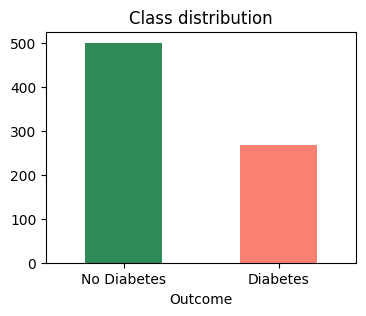

In [ ]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Class balance
print(df["Outcome"].value_counts())
plt.figure(figsize=(4, 3))
df["Outcome"].map({0: "No Diabetes", 1: "Diabetes"}).value_counts().plot(kind="bar", color=["seagreen", "salmon"])
plt.title("Class distribution"); plt.xticks(rotation=0); plt.show()

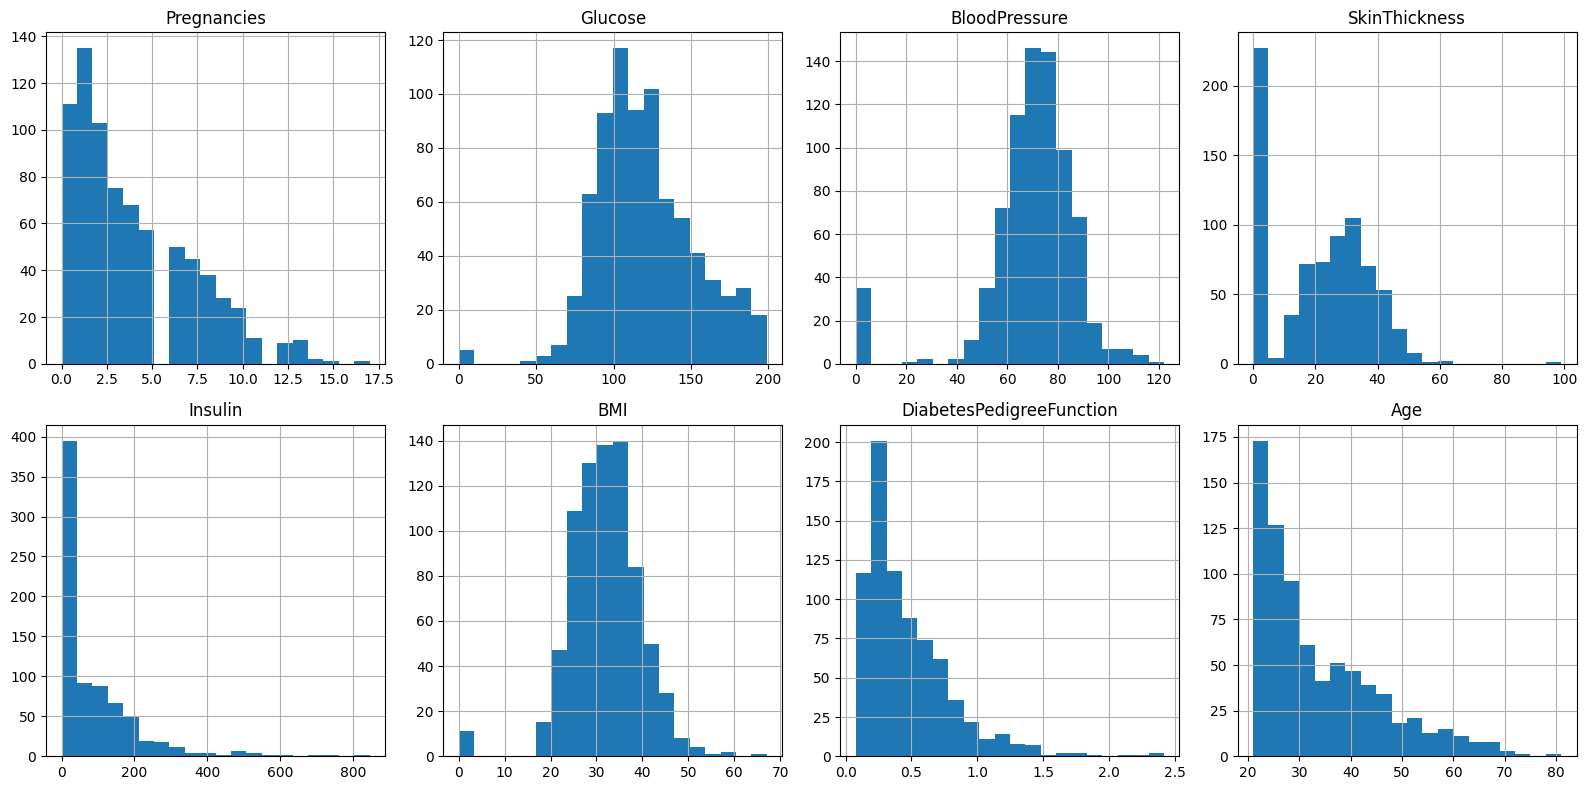

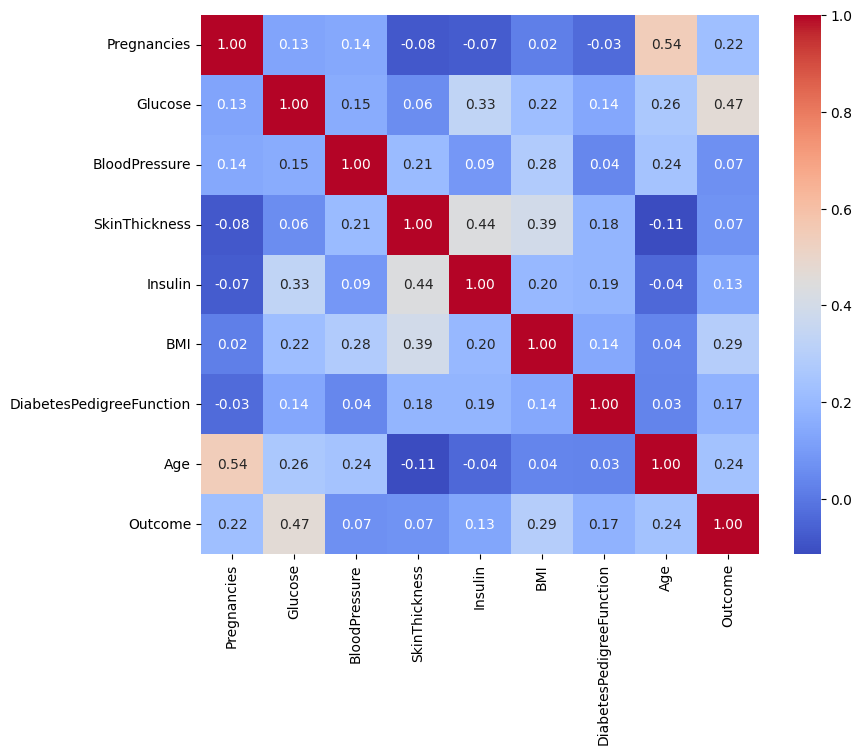

In [ ]:
# Visualize key features + correlation
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flatten(), df.columns[:-1]):
    df[col].hist(ax=ax, bins=20)
    ax.set_title(col)
plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

TASK - 2

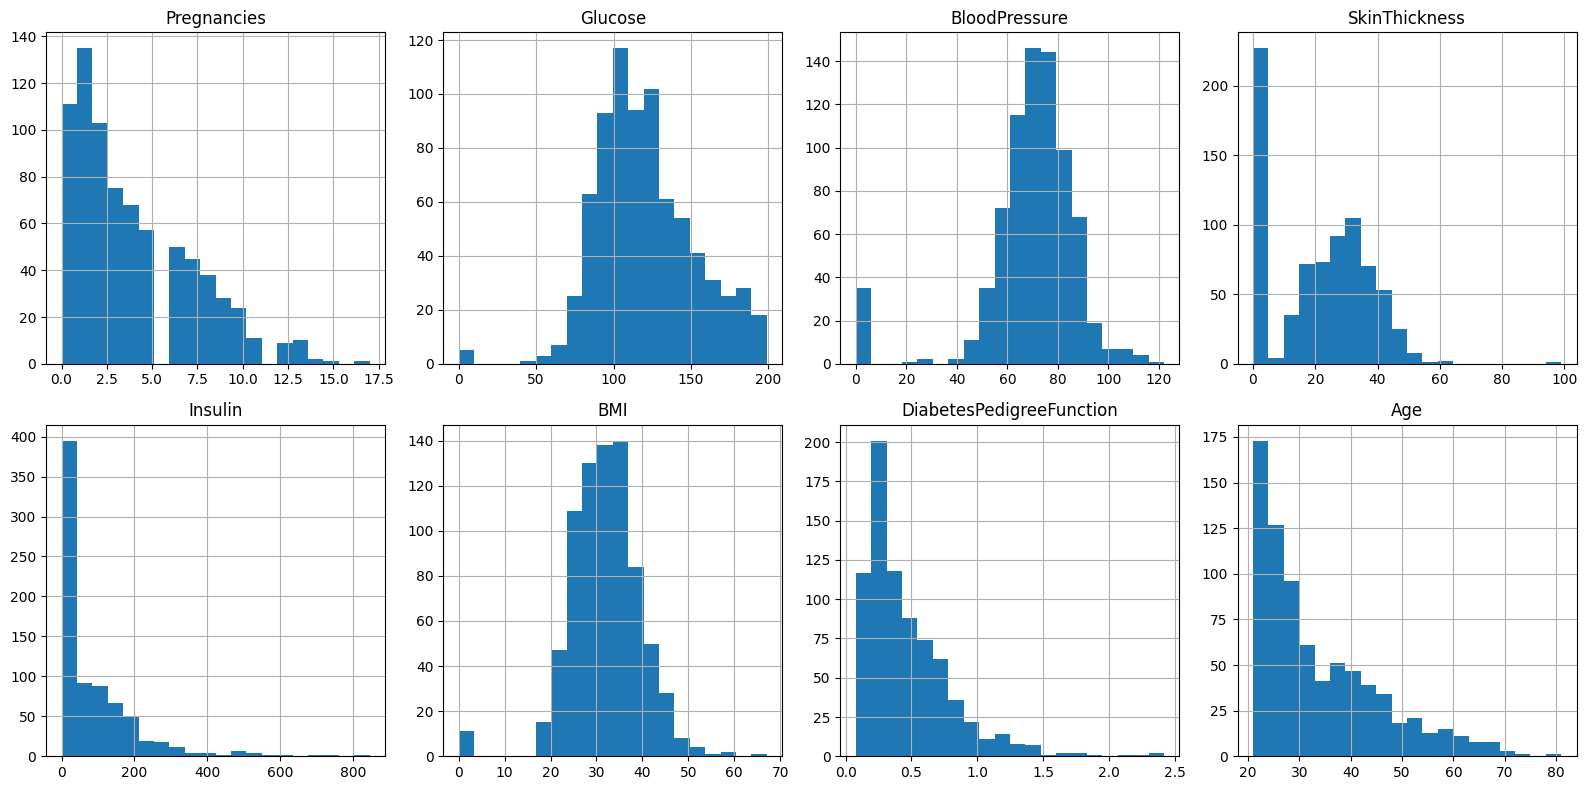

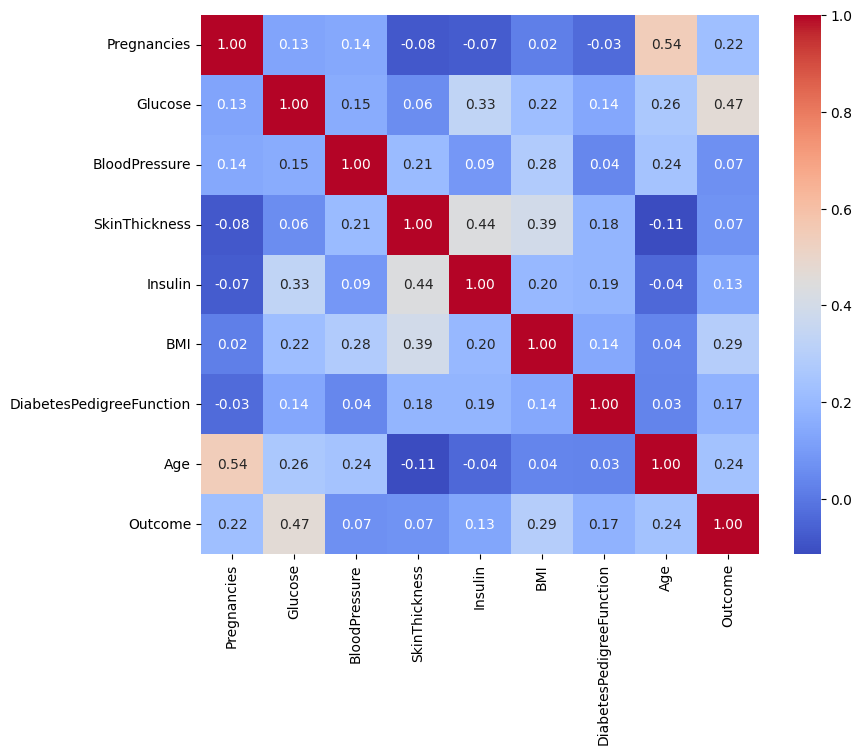

In [ ]:
# Visualize key features + correlation
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flatten(), df.columns[:-1]):
    df[col].hist(ax=ax, bins=20)
    ax.set_title(col)
plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

In [ ]:
X = df.drop(columns="Outcome").values
y = df["Outcome"].values

# 70 / 15 / 15 stratified split
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)
print(len(X_train), len(X_val), len(X_test))

537 115 116


In [ ]:
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

TASK - 3

In [ ]:
def build_model(meta, n_neurons=12, activation="relu", init="glorot_uniform",
                 dropout=0.2, learning_rate=0.001):
    n_features_in = meta["n_features_in_"]   # scikeras passes this in automatically
    model = keras.Sequential([
        keras.Input(shape=(n_features_in,)),
        layers.Dense(n_neurons, activation=activation, kernel_initializer=init),
        layers.Dropout(dropout),
        layers.Dense(max(n_neurons // 2, 2), activation=activation, kernel_initializer=init),
        layers.Dense(1, activation="sigmoid", kernel_initializer=init),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model

clf = KerasClassifier(
    model=build_model, verbose=0, random_state=SEED,
    n_neurons=12, activation="relu", init="glorot_uniform",
    dropout=0.2, learning_rate=0.001, batch_size=10, epochs=20,
)

In [ ]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

def tune_stage(param_grid, current_best_params):
    clf.set_params(**current_best_params)
    gs = GridSearchCV(estimator=clf, param_grid=param_grid, cv=cv, scoring="accuracy", n_jobs=1)
    gs.fit(X_train_s, y_train)
    print(f"Best for {list(param_grid.keys())}: {gs.best_params_}  (CV accuracy = {gs.best_score_:.4f})")
    return gs.best_params_

best = dict(batch_size=10, epochs=20, learning_rate=0.001, init="glorot_uniform",
            activation="relu", dropout=0.2, n_neurons=12)

In [ ]:
best.update(tune_stage({"batch_size": [10, 20, 40], "epochs": [10, 20, 50]}, best))

Best for ['batch_size', 'epochs']: {'batch_size': 10, 'epochs': 20}  (CV accuracy = 0.7691)


In [ ]:
best.update(tune_stage({"learning_rate": [0.1, 0.01, 0.001, 0.0001]}, best))

In [ ]:
best.update(tune_stage({"init": ["glorot_uniform", "normal", "uniform", "he_normal"]}, best))

Best for ['init']: {'init': 'uniform'}  (CV accuracy = 0.7803)


In [ ]:
best.update(tune_stage({"activation": ["relu", "tanh", "sigmoid"]}, best))

Best for ['activation']: {'activation': 'tanh'}  (CV accuracy = 0.7821)


In [ ]:
best.update(tune_stage({"dropout": [0.0, 0.1, 0.2, 0.3, 0.4]}, best))

Best for ['dropout']: {'dropout': 0.0}  (CV accuracy = 0.7821)


In [ ]:
best.update(tune_stage({"n_neurons": [4, 8, 12, 16, 20]}, best))

print("\nFinal best hyperparameters found:")
print(best)

Best for ['n_neurons']: {'n_neurons': 20}  (CV accuracy = 0.7840)

Final best hyperparameters found:
{'batch_size': 10, 'epochs': 20, 'learning_rate': 0.001, 'init': 'uniform', 'activation': 'tanh', 'dropout': 0.0, 'n_neurons': 20}


Test accuracy: 0.7586206896551724
              precision    recall  f1-score   support

 No Diabetes       0.77      0.89      0.83        75
    Diabetes       0.72      0.51      0.60        41

    accuracy                           0.76       116
   macro avg       0.75      0.70      0.71       116
weighted avg       0.75      0.76      0.75       116



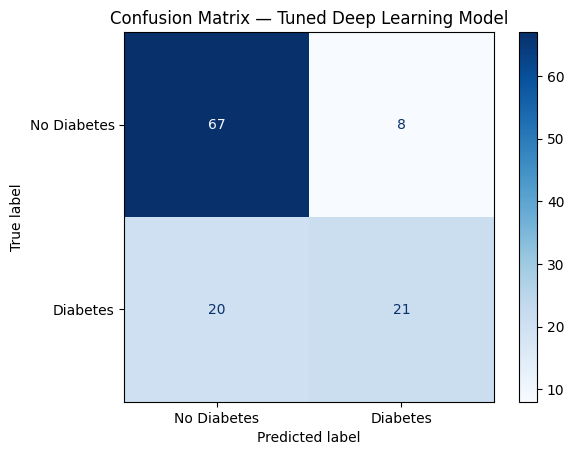

In [ ]:
clf.set_params(**best)
clf.fit(X_train_s, y_train)

y_pred = clf.predict(X_test_s)
y_proba = clf.predict_proba(X_test_s)[:, 1]

print("Test accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=["No Diabetes", "Diabetes"]))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["No Diabetes", "Diabetes"]).plot(cmap="Blues")
plt.title("Confusion Matrix — Tuned Deep Learning Model")
plt.show()